# See what preprocessing does

`scripts/preprocess.py` turns each raw clip into the clean, fixed-size input the models train on. This notebook follows **one clip** through it, so each step is something you can see:

1. **Before:** the raw dots, straight from MediaPipe.
2. **After:** centred, resized, mirrored and fixed to 64 frames.
3. **The mask:** which dots were missing.
4. **Augmentation:** the random changes made to clips during training.

Paths are relative to `ml/`, which is where VS Code runs notebooks in this repo.

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

sys.path.append("scripts")  # so we can use the real preprocessing and augmentation code
from preprocess import KEEP, prepare_clip
from training import augment

clips = pd.read_csv("data/processed/clips.csv")
landmarks = np.load("data/processed/landmarks.npy", mmap_mode="r")  # mmap: read from disk only when needed

## Pick a clip

A "hello" signed with the **left** hand, so we can see the mirroring step too. `start` and `length` say which rows of `landmarks.npy` hold this clip.

In [2]:
clip = clips[clips["sequence_id"] == 1484918207].iloc[0]
raw = landmarks[clip["start"]:clip["start"] + clip["length"]]  # (frames, 94, 3): x, y, z of 94 dots
print(f'"{clip["sign"]}" by participant {clip["participant_id"]}: {len(raw)} frames, shape {raw.shape}')

"hello" by participant 27610: 48 frames, shape (48, 105, 3)


## A function to draw one frame

Preprocessing keeps 85 of the 105 dots, in this order (see the top of `preprocess.py`):

| Positions | Dots | Drawn as |
|---|---|---|
| 0-19 | outer lips | red dots |
| 20-40 | a hand (MediaPipe's "left" hand; after mirroring, the *other* hand) | blue lines |
| 41-52 | upper body: shoulders, elbows, wrists | grey lines |
| 53-73 | a hand (MediaPipe's "right" hand; after mirroring, the *dominant* hand) | orange lines |
| 74-84 | face, from the body model: nose, eyes, ears, mouth corners | green dots |

Each hand has 21 dots: the wrist (0) and four up each finger. The lists below say which dots to join with a line.

In [3]:
HAND_CONNECTIONS = [
    (0, 1), (1, 2), (2, 3), (3, 4),  # thumb
    (0, 5), (5, 6), (6, 7), (7, 8),  # index finger
    (9, 10), (10, 11), (11, 12),  # middle finger
    (13, 14), (14, 15), (15, 16),  # ring finger
    (0, 17), (17, 18), (18, 19), (19, 20),  # little finger
    (5, 9), (9, 13), (13, 17),  # palm
]
BODY_CONNECTIONS = [(41, 42), (41, 43), (43, 45), (42, 44), (44, 46)]  # shoulders, upper arms, forearms
HANDS = {20: "tab:blue", 53: "tab:orange"}  # first position of each hand -> colour


def draw_frame(ax, xy, missing):
    """Draw one frame's 85 dots. xy is (85, 2); missing is (85,) and True for dots to skip."""
    def line(a, b, colour):
        if not (missing[a] or missing[b]):
            ax.plot(*xy[[a, b]].T, color=colour, linewidth=1)

    for a, b in BODY_CONNECTIONS:
        line(a, b, "grey")
    for start, colour in HANDS.items():
        for a, b in HAND_CONNECTIONS:
            line(start + a, start + b, colour)
    lips = [i for i in range(20) if not missing[i]]
    ax.scatter(*xy[lips].T, s=2, color="tab:red")
    face = [i for i in range(74, 85) if not missing[i]]
    ax.scatter(*xy[face].T, s=4, color="tab:green")


def draw_clip(xy, missing, title, n_frames=8):
    """Draw n_frames evenly spaced frames that have at least one dot, all on the same axes."""
    real_frames = np.flatnonzero(~missing.all(axis=1))
    shown = real_frames[np.linspace(0, len(real_frames) - 1, n_frames).astype(int)]
    seen = xy[~missing]  # every dot that was there, to set shared axis limits

    fig, axes = plt.subplots(1, n_frames, figsize=(2.2 * n_frames, 2.8))
    for ax, frame in zip(axes, shown):
        draw_frame(ax, xy[frame], missing[frame])
        ax.set_title(f"frame {frame}", fontsize=8)
        ax.set_xlim(seen[:, 0].min() - 0.05, seen[:, 0].max() + 0.05)
        ax.set_ylim(seen[:, 1].max() + 0.05, seen[:, 1].min() - 0.05)  # flipped: y grows downwards, as in images
        ax.set_aspect("equal")
    fig.suptitle(title)
    plt.show()

## 1. Before preprocessing

Only the 85 dots are kept and z is dropped, nothing else. The numbers on the axes are **fractions of the camera image**: x = 0.5 means halfway across the picture.

Things to notice:
- The signer isn't in the middle of the picture, and their size depends on how close they stood.
- Only the **blue** hand moves, because this person signs with their left hand.
- The **orange** hand is never drawn: MediaPipe never found it in this clip.
- The **lips** vanish in some frames (6, 20, 26), probably because the hand passes in front of the face. MediaPipe misses dots like this all the time, which is why we need the mask (step 3).
- The **green** face dots never vanish: they come from the body model, which is estimated in every frame. They tell the model where the eyes, ears and nose are even when the hand covers the face.

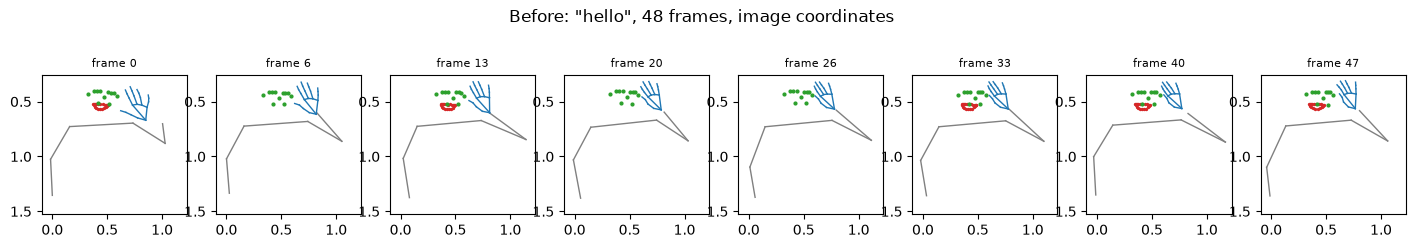

In [4]:
before = raw[:, KEEP, :2].astype(np.float32)  # (frames, 85, 2)
before_missing = np.isnan(before).any(axis=2)  # (frames, 85)
draw_clip(before, before_missing, f'Before: "{clip["sign"]}", {len(before)} frames, image coordinates')

## 2. After preprocessing

`prepare_clip` is the function from `preprocess.py` that runs on every clip. Look at what changed:
- **Centred:** the point between the shoulders is now at (0, 0) in every frame.
- **Resized:** the axes are now in **shoulder widths**. The shoulders are 1 apart, whoever is signing and however far away they stood.
- **Mirrored:** the signing hand is now **orange**, in the dominant-hand slot, and the picture is flipped left to right. Every clip now looks right-handed, so the model doesn't need to learn every sign twice.
- **64 frames:** the frame numbers now run 0-63.

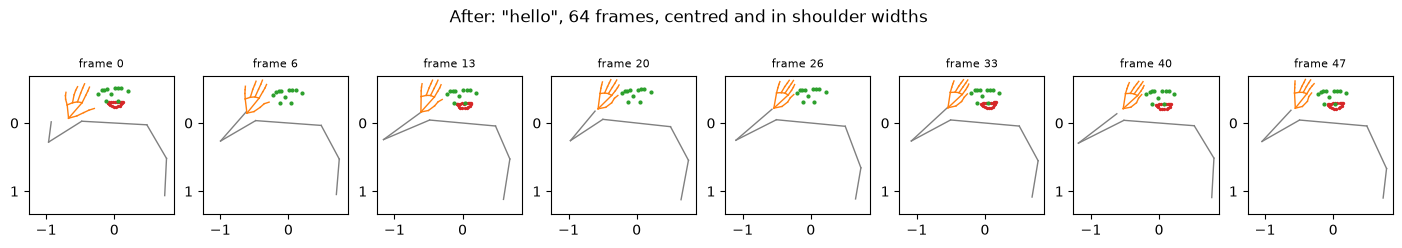

In [5]:
after, after_missing = prepare_clip(raw)  # (64, 85, 2) and (64, 85)
draw_clip(after, after_missing, f'After: "{clip["sign"]}", 64 frames, centred and in shoulder widths')

The first frame as numbers, (x, y) for each shoulder. Before, they are fractions of the image. After, they sit on either side of (0, 0), about 1 apart. It's not exactly 1 because the scale comes from the clip's *typical* shoulder width, and people move a little from frame to frame.

(The two shoulders also swapped places: mirroring swaps every left dot with its right partner.)

In [6]:
print("Before, shoulders:", before[0, [41, 42]].round(3).tolist())
print("After,  shoulders:", after[0, [41, 42]].round(3).tolist())

Before, shoulders: [[0.734000027179718, 0.6959999799728394], [0.15800000727176666, 0.7279999852180481]]
After,  shoulders: [[0.4779999852180481, 0.026000000536441803], [-0.4779999852180481, -0.026000000536441803]]


## 3. The mask

The model needs the same input size for every clip, so a missing dot can't simply be left out. It is set to 0 instead, and the **mask** marks it, so the model knows "this 0 means *not seen*, not *at the centre*".

Below, each row is one of the 64 frames and each column one of the 85 dots. **Dark = missing.**
- The **blue hand's columns (20-40)** are dark: after mirroring, that slot holds the right hand, which was never seen.
- The **bottom rows** are completely dark: the clip was shorter than 64 frames, so empty "padding" frames were added at the end.
- The **gaps in the lips** are the frames where the face was hidden, and the thin lines in the **dominant hand** are frames where MediaPipe lost the hand for a moment.
- The **body** and **face** are never missing: MediaPipe always guesses where the shoulders, arms, eyes and ears are.

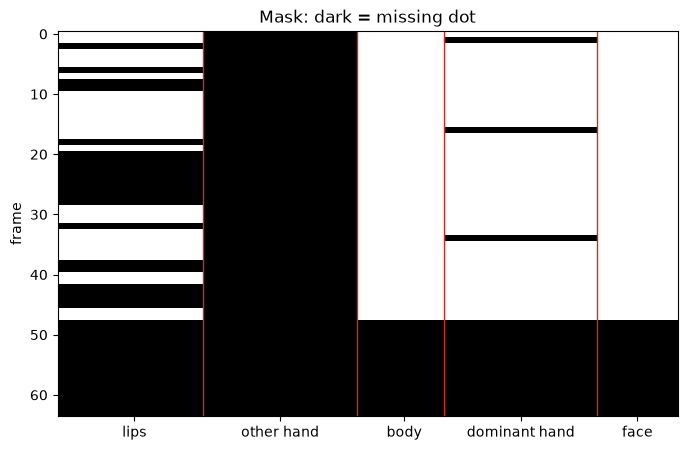

Real frames: 48, padding frames: 16


In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(after_missing, cmap="Greys", aspect="auto", interpolation="nearest")
for edge in [19.5, 40.5, 52.5, 73.5]:  # boundaries between lips, other hand, body, dominant hand, face
    ax.axvline(edge, color="tab:red", linewidth=1)
ax.set_xticks([10, 30, 47, 63, 79], ["lips", "other hand", "body", "dominant hand", "face"])
ax.set_ylabel("frame")
ax.set_title("Mask: dark = missing dot")
plt.show()
print(f"Real frames: {(~after_missing.all(axis=1)).sum()}, padding frames: {after_missing.all(axis=1).sum()}")

## 4. Augmentation

During training, `augment` (in `training.py`) changes every clip slightly at random, **each time** the model sees it:

- plays it 0.8 to 1.2 times as fast (people sign at different speeds),
- tilts it by up to 15°,
- makes it 0.8 to 1.2 times as big,
- shifts it by up to a tenth of a shoulder width,
- turns and resizes each hand a little on its own, around its wrist (people's hands differ in size and angle),
- hides the lips in 1 clip in 5, so the model can't lean on them too much,
- drops about 1 frame in 10.

The model never sees exactly the same clip twice, so it has to learn the shape of the movement instead of memorising exact dot positions.

Here is frame 20 of our clip, unchanged and then in four random versions. (Because of the speed change, a random version's frame 20 may come from a slightly earlier or later moment of the sign.) The changes are small on purpose: just enough that the model can't memorise exact positions. Remove the `torch.manual_seed` line to get new versions every time you run the cell.

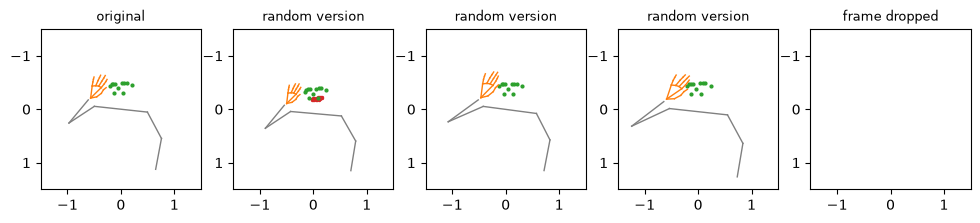

In [8]:
frame = 20
torch.manual_seed(18)  # fixed so the picture is the same each run
x = torch.from_numpy(after).unsqueeze(0)  # augment works on batches: (1 clip, 64, 85, 2)
mask = torch.from_numpy(after_missing).unsqueeze(0)

fig, axes = plt.subplots(1, 5, figsize=(12, 3))
draw_frame(axes[0], after[frame], after_missing[frame])
axes[0].set_title("original", fontsize=9)
for ax in axes[1:]:
    new_x, new_mask = augment(x, mask)
    if new_mask[0, frame].all():
        ax.set_title("frame dropped", fontsize=9)
    else:
        draw_frame(ax, new_x[0, frame].numpy(), new_mask[0, frame].numpy())
        ax.set_title("random version", fontsize=9)
for ax in axes:
    ax.set_xlim(-1.5, 1.5)
    ax.set_ylim(1.5, -1.5)
    ax.set_aspect("equal")
plt.show()

## Try it yourself

- Change the `sequence_id` in **Pick a clip**. Some to try: `1787748341` (another left-handed "hello"), or find more with `clips[clips["sign"] == "dog"].head()`.
- Pick a **right-handed** clip: the "After" picture should *not* be flipped.
- Pick a clip **longer than 64 frames** (`clips[clips["length"] > 100].head()`): the mask has no padding rows, because frames were skipped evenly to fit 64.